# HW1 Part E: Sensitivity analysis

Run the Part D SEIR model on a grid of

$$\beta \in [0.05 \times 10^{-3},\; 0.25 \times 10^{-3}], \qquad \gamma \in [0.05,\; 0.25]$$

with at least 5 values each. For every $(\beta, \gamma)$ pair compute the peak number infected and the total new infections over the first 365 days. Show both as heatmaps or contour plots and mark the line $R_0 = 1$.

Discuss the public-health implications: $\beta$ relates to social distancing, $\gamma$ to medical treatment.


In [1]:
# part d code copied 
import numpy as np

def forwardEuler(f, y0, t):
    # array of 0's to store inital value and all subsequent solved values
    y = np.zeros((len(t),) + np.shape(y0))
    # add initial condition to beginning of the array
    y[0] = y0
    # iterate over each time step
    for i in range(1, len(t)):
        #compute change in time 
        dt = t[i] - t[i-1]
        #previous time step solution plus time step change
        # multiplied by the derivative at the previous time step
        y[i] = y[i-1] + dt * f(y[i-1], t[i-1])
    return y


def seir_ders(y, beta, gamma, sigma, mu, N):

    S, E, I, R = y
    dSdt = mu*N - beta * S * I - mu*S
    dEdt = beta * S * I - (sigma+mu )*E
    dIdt = sigma * E - (gamma + mu) * I
    dRdt = gamma * I - mu*R
    return np.array([dSdt, dEdt, dIdt, dRdt])

def seir_model(y0, t, beta, gamma, sigma, mu, N):
    def f(y, t):
        return seir_ders(y, beta, gamma, sigma, mu, N)
    return forwardEuler(f, y0, t)

In [2]:
# E.i  run the SEIR model on a grid of beta and gamma values (everything else as in part D)
N = 2000
sigma = 0.25
mu = 0.005
y0 = np.array([1980, 15, 5, 0])
# first 365 days with an Euler step of 0.1 day
t = np.arange(0, 365.1, 0.1)
dt = t[1] - t[0]

# 9 values each, covering the ranges in the handout (at least 5 required);
# steps of 0.025e-3 and 0.025 so the part D pair (0.125e-3, 0.1) is on the grid
betas = np.linspace(0.05e-3, 0.25e-3, 9)
gammas = np.linspace(0.05, 0.25, 9)

# E.ii  for each (beta, gamma) pair store the peak number infected and the total new infections
# rows = beta, columns = gamma
peak_I = np.zeros((len(betas), len(gammas)))
total_new = np.zeros((len(betas), len(gammas)))
R0_grid = np.zeros((len(betas), len(gammas)))

for i, beta in enumerate(betas):
    for j, gamma in enumerate(gammas):
        y = seir_model(y0, t, beta, gamma, sigma, mu, N)
        S, E, I, R = y.T
        peak_I[i, j] = I.max()
        # new infections per day is the flow out of S into E, beta*S*I;
        # add it up over all time steps to get the total over 365 days
        total_new[i, j] = np.sum(beta * S * I) * dt
        R0_grid[i, j] = beta * N * sigma / ((sigma + mu) * (gamma + mu))

# the part D parameter pair sits in the middle of the grid
i_b, j_g = 3, 2   # beta = 0.125e-3, gamma = 0.1
print(f"Part D pair (beta={betas[i_b]:.6f}, gamma={gammas[j_g]:.2f}):  "
      f"R0 = {R0_grid[i_b, j_g]:.2f}, peak I = {peak_I[i_b, j_g]:.0f}, total new infections = {total_new[i_b, j_g]:.0f}")
print(f"Peak I ranges from {peak_I.min():.0f} to {peak_I.max():.0f} people over the grid")
print(f"Total new infections ranges from {total_new.min():.0f} to {total_new.max():.0f} over the grid")
print(f"Number of (beta, gamma) pairs with R0 < 1: {(R0_grid < 1).sum()} of {R0_grid.size}")

Part D pair (beta=0.000125, gamma=0.10):  R0 = 2.33, peak I = 318, total new infections = 3075
Peak I ranges from 8 to 1040 people over the grid
Total new infections ranges from 12 to 4865 over the grid
Number of (beta, gamma) pairs with R0 < 1: 16 of 81


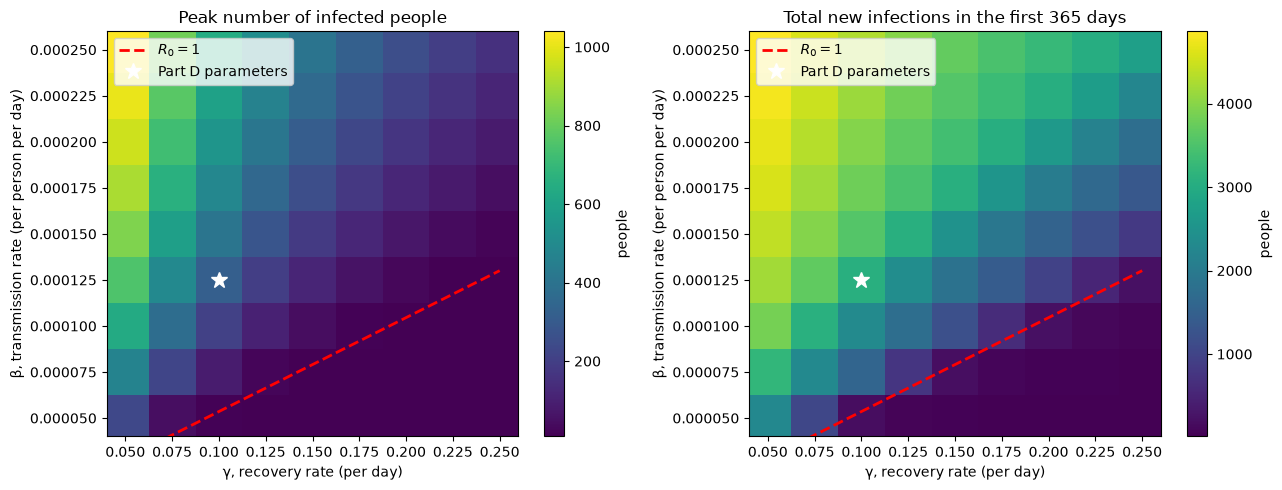

In [3]:
import matplotlib.pyplot as plt

# R0 = 1 happens when beta = (sigma + mu)(gamma + mu) / (N sigma); plot this as a line over each heatmap
gam_line = np.linspace(gammas[0], gammas[-1], 200)
beta_line = (sigma + mu) * (gam_line + mu) / (N * sigma)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, title in [(axes[0], peak_I, 'Peak number of infected people'),
                     (axes[1], total_new, 'Total new infections in the first 365 days')]:
    # x axis = gamma, y axis = beta (rows of Z are beta, so no transpose needed)
    im = ax.pcolormesh(gammas, betas, Z, shading='nearest', cmap='viridis')
    fig.colorbar(im, ax=ax, label='people')
    ax.plot(gam_line, beta_line, 'r--', linewidth=2, label='$R_0 = 1$')
    ax.plot(0.1, 0.125e-3, 'w*', markersize=12, label='Part D parameters')
    ax.set_xlim(gammas[0] - 0.01, gammas[-1] + 0.01)
    ax.set_ylim(betas[0] - 0.01e-3, betas[-1] + 0.01e-3)
    ax.set_xlabel('γ, recovery rate (per day)')
    ax.set_ylabel('β, transmission rate (per person per day)')
    ax.set_title(title)
    ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('partE_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

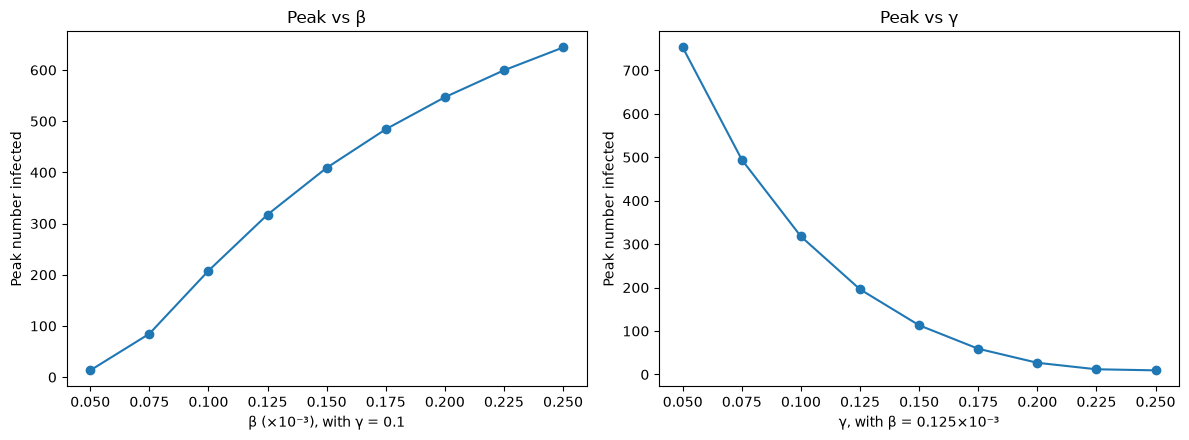

beta from 0.000050 to 0.000250 (gamma = 0.1):  peak goes 13 -> 644
gamma from 0.05 to 0.25 (beta = 0.125e-3):  peak goes 9 (gamma=0.25) -> 753 (gamma=0.05)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(betas * 1e3, peak_I[:, j_g], 'o-')
axes[0].set_xlabel('β (×10⁻³), with γ = 0.1')
axes[0].set_ylabel('Peak number infected')
axes[0].set_title('Peak vs β')
axes[1].plot(gammas, peak_I[i_b, :], 'o-')
axes[1].set_xlabel('γ, with β = 0.125×10⁻³')
axes[1].set_ylabel('Peak number infected')
axes[1].set_title('Peak vs γ')
fig.tight_layout()
fig.savefig('partE_peak_vs_beta_gamma.png', dpi=150, bbox_inches='tight')
plt.show()

# both parameters vary by the same factor of 5 over the grid
print(f"beta from {betas[0]:.6f} to {betas[-1]:.6f} (gamma = 0.1):  peak goes {peak_I[0, j_g]:.0f} -> {peak_I[-1, j_g]:.0f}")
print(f"gamma from {gammas[0]:.2f} to {gammas[-1]:.2f} (beta = 0.125e-3):  peak goes {peak_I[i_b, -1]:.0f} (gamma=0.25) -> {peak_I[i_b, 0]:.0f} (gamma=0.05)")

In [5]:
# check that gamma matters beyond R0: hold R0 at 3 and change gamma, picking beta to keep R0 fixed
R0_fixed = 3
for g in [0.05, 0.1, 0.2]:
    b = R0_fixed * (sigma + mu) * (g + mu) / (N * sigma)
    y = seir_model(y0, t, b, g, sigma, mu, N)
    S, E, I, R = y.T
    print(f"gamma = {g:.2f}, beta = {b:.6f}, R0 = {R0_fixed}:  peak I = {I.max():.0f},  total new infections = {np.sum(b * S * I) * dt:.0f}")

gamma = 0.05, beta = 0.000084, R0 = 3:  peak I = 536,  total new infections = 3488
gamma = 0.10, beta = 0.000161, R0 = 3:  peak I = 443,  total new infections = 3678
gamma = 0.20, beta = 0.000314, R0 = 3:  peak I = 338,  total new infections = 3589


E.ii

Both heatmaps have the same shape. The peak and the total number of infections are largest at high beta and low gamma (top left, R0 up to 8.9) and fall off toward low beta and high gamma. The dashed line is R0 = 1, which for this model is beta = (sigma+mu)*(gamma+mu)/(N*sigma). Below it R0 is less than 1 (16 of the 81 pairs) and there is no epidemic, the peak is only 8 to 13 people, which is just the 20 people who start out exposed or infected plus a short chain of cases that dies out, and the total new infections over the year is between 12 and about 220, with the larger totals in the cells just under the line where R0 is 0.93 to 0.96 and each case almost replaces itself. The peak and the total rise steeply across the line, for example along the part D row one grid step in beta takes R0 from 0.93 to 1.40 and the total from 172 to 1568, so R0 = 1 is the threshold for whether an outbreak takes off and it depends on beta and gamma together. For the part D pair (beta = 0.000125, gamma = 0.1, white star) R0 = 2.33 with a peak of 318 and 3075 new infections in the year. Both parameters vary by a factor of 5 on the grid, and along the part D row and column the peak goes from 13 to 644 as beta increases but from 9 to 753 as gamma decreases, so gamma actually has a slightly larger effect on the peak, contrary to my hypothesis. This is because gamma affects the peak in two ways, through R0 like beta does but also through how long each person stays infectious (1/gamma days), so a lower gamma piles more people up in I at the same time. I checked this by holding R0 at 3 and changing gamma: with gamma = 0.05, 0.1 and 0.2 the peak is 536, 443 and 338 while the total stays at about 3500 to 3700. For the total number of infections the two are about equal (172 to 4287 along beta, 217 to 4196 along gamma) since the total depends mainly on R0.

E.iii

beta depends on how often susceptible and infected people come into contact, so social distancing, lockdowns and masks lower beta. gamma is one over the infectious period, so treatment that clears the infection faster raises gamma, and isolating people once they test positive does the same thing since it removes them from the infectious pool sooner. The heatmaps show two things an intervention can do. One is to end the epidemic by pushing R0 below 1, which from the part D pair means cutting beta to about 0.000054 (a 57% reduction in transmission) or raising gamma to about 0.24 (an infectious period of about 4 days instead of 10), or some combination along the red line. The other is to flatten the curve even if R0 stays above 1, for example raising gamma from 0.1 to 0.15 cuts the peak from 318 to 113 and the yearly total from 3075 to 1839, and the peak is what decides whether hospitals are overwhelmed. Since gamma affects the peak slightly more, treatment and fast isolation are at least as useful as distancing for keeping the peak down, while both reduce the total number infected about equally. A limitation is that beta and gamma are held constant for a whole year, when in reality interventions and behavior change over time.